# 04 — Avaliação Final, Limiar e Interpretação

Aqui o conjunto de teste (**nunca visto**) é usado pela primeira vez.

Conteúdo:
1. Métricas no conjunto de teste (ROC-AUC, PR-AUC, recall, precisão, F1)
2. Matrizes de confusão e curvas ROC / Precision-Recall
3. Análise do **limiar de corte** (o 0,5 padrão nem sempre é o melhor)
4. Importância das features (permutation importance + odds ratios)
5. Conclusões e recomendações de negócio

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", 100)

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import joblib
from sklearn.inspection import permutation_importance
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

bundle = joblib.load(ROOT / "models" / "modelo_churn.joblib")
pre = joblib.load(ROOT / "models" / "preprocessor.joblib")
splits = joblib.load(ROOT / "data" / "processed" / "splits.joblib")

modelo, nome_modelo = bundle["modelo"], bundle["nome"]
X_test = splits["X_test"]
y_test = splits["y_test"]
X_test_t = pre.transform(X_test)

proba = modelo.predict_proba(X_test_t)[:, 1]
pred = (proba >= 0.5).astype(int)
print(f"Modelo avaliado: {nome_modelo} | Base de teste: {X_test.shape[0]} clientes")

Modelo avaliado: Random Forest | Base de teste: 1407 clientes


## 1. Métricas no conjunto de teste (limiar = 0,5)

,valor
ROC-AUC,0.8347
PR-AUC,0.6409
Acurácia,0.7413
Precisão,0.5086
Recall,0.7941
F1,0.6200


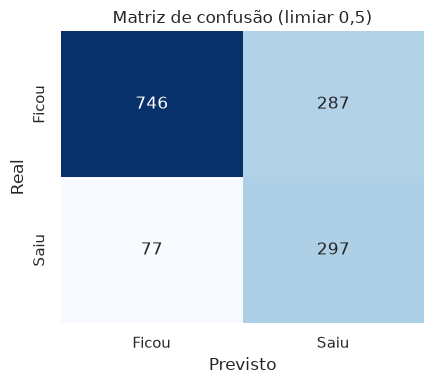

In [2]:
metricas = {
    "ROC-AUC": roc_auc_score(y_test, proba),
    "PR-AUC": average_precision_score(y_test, proba),
    "Acurácia": accuracy_score(y_test, pred),
    "Precisão": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
}
display(pd.Series(metricas, name="valor").round(4).to_frame())

cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Ficou", "Saiu"], yticklabels=["Ficou", "Saiu"])
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusão (limiar 0,5)")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

> **Recall** = de todos os clientes que realmente saíram, quantos o modelo detectou.
> Em churn, errar um cliente que sai custa mais caro que um falso alarme →
> por isso a análise de limiar abaixo.

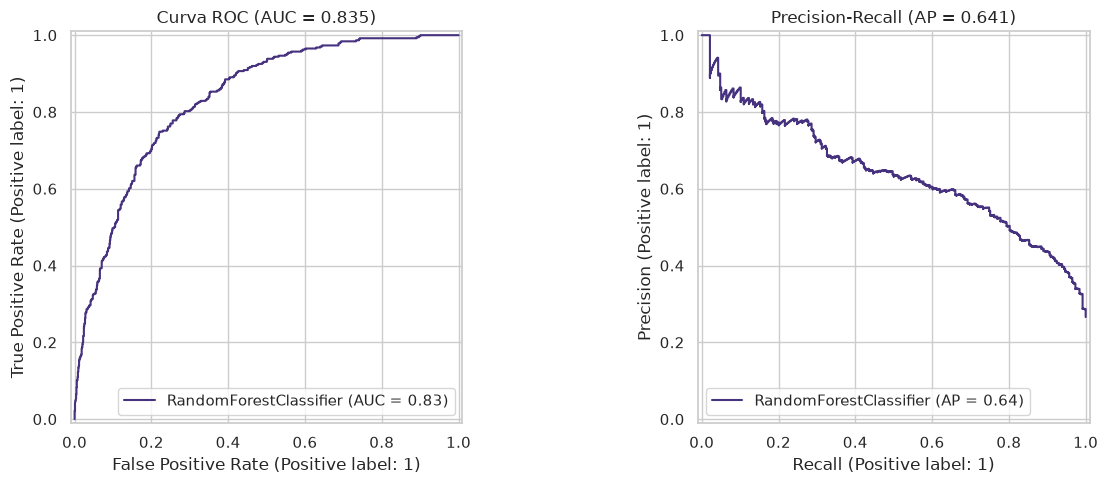

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_estimator(modelo, X_test_t, y_test, ax=axes[0])
axes[0].set_title(f"Curva ROC (AUC = {metricas['ROC-AUC']:.3f})")
PrecisionRecallDisplay.from_estimator(modelo, X_test_t, y_test, ax=axes[1])
axes[1].set_title(f"Precision-Recall (AP = {metricas['PR-AUC']:.3f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Escolha do limiar de corte

,limiar,precisao,recall,f1
0,0.20,0.3802,0.9545,0.5438
1,0.25,0.3993,0.9385,0.5603
2,0.30,0.4218,0.9091,0.5763
3,0.35,0.4467,0.8850,0.5937
4,0.40,0.4663,0.8503,0.6023
5,0.45,0.4827,0.8209,0.6079
6,0.50,0.5086,0.7941,0.6200
7,0.55,0.5300,0.7567,0.6233
8,0.60,0.5608,0.7032,0.6240
9,0.65,0.5924,0.6257,0.6086


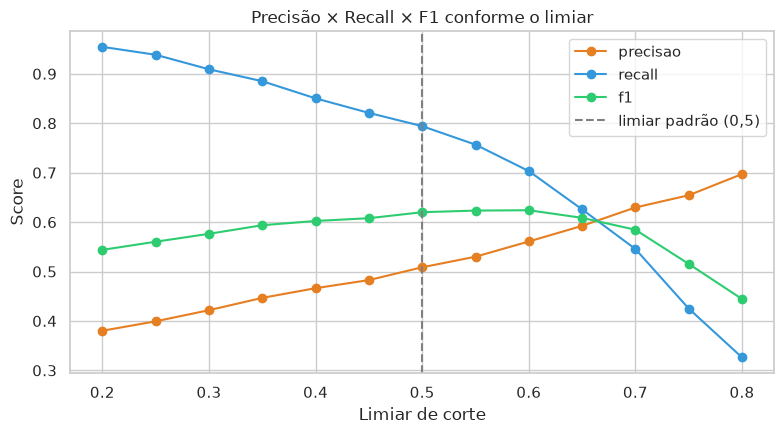

Melhor limiar para F1: 0.60


In [4]:
faixa = np.arange(0.20, 0.81, 0.05)
tabela_limiar = pd.DataFrame({
    "limiar": faixa,
    "precisao": [precision_score(y_test, proba >= t, zero_division=0) for t in faixa],
    "recall": [recall_score(y_test, proba >= t) for t in faixa],
    "f1": [f1_score(y_test, proba >= t) for t in faixa],
})
tabela_limiar = tabela_limiar.round(4)
display(tabela_limiar)

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, cor in [("precisao", "#e67e22"), ("recall", "#3498db"), ("f1", "#2ecc71")]:
    ax.plot(tabela_limiar["limiar"], tabela_limiar[col], marker="o", label=col, color=cor)
ax.axvline(0.5, ls="--", c="gray", label="limiar padrão (0,5)")
ax.set_xlabel("Limiar de corte")
ax.set_ylabel("Score")
ax.set_title("Precisão × Recall × F1 conforme o limiar")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "09_analise_limiar.png", dpi=150, bbox_inches="tight")
plt.show()

melhor_limiar = tabela_limiar.loc[tabela_limiar["f1"].idxmax(), "limiar"]
print(f"Melhor limiar para F1: {melhor_limiar:.2f}")

,limiar_0.50,limiar_0.60
ROC-AUC,0.8347,0.8347
PR-AUC,0.6409,0.6409
Acurácia,0.7413,0.7747
Precisão,0.5086,0.5608
Recall,0.7941,0.7032
F1,0.6200,0.6240


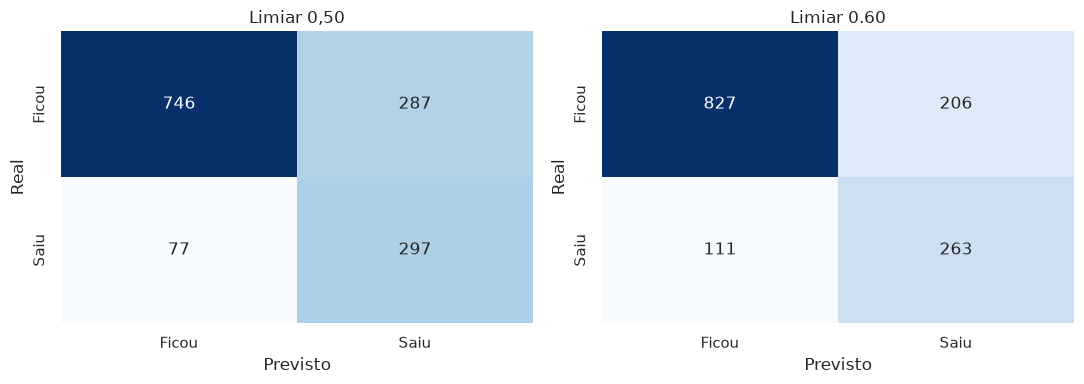

In [5]:
pred_novo = (proba >= melhor_limiar).astype(int)

comparacao = pd.DataFrame({
    "limiar_0.50": metricas,
    f"limiar_{melhor_limiar:.2f}": {
        "ROC-AUC": metricas["ROC-AUC"],           # não muda com o limiar
        "PR-AUC": metricas["PR-AUC"],
        "Acurácia": accuracy_score(y_test, pred_novo),
        "Precisão": precision_score(y_test, pred_novo),
        "Recall": recall_score(y_test, pred_novo),
        "F1": f1_score(y_test, pred_novo),
    },
})
display(comparacao.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, p, titulo in [(axes[0], pred, "Limiar 0,50"), (axes[1], pred_novo, f"Limiar {melhor_limiar:.2f}")]:
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax, xticklabels=["Ficou", "Saiu"], yticklabels=["Ficou", "Saiu"])
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_title(titulo)
plt.tight_layout()
plt.savefig(FIG_DIR / "10_comparacao_limiares.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Importância das features

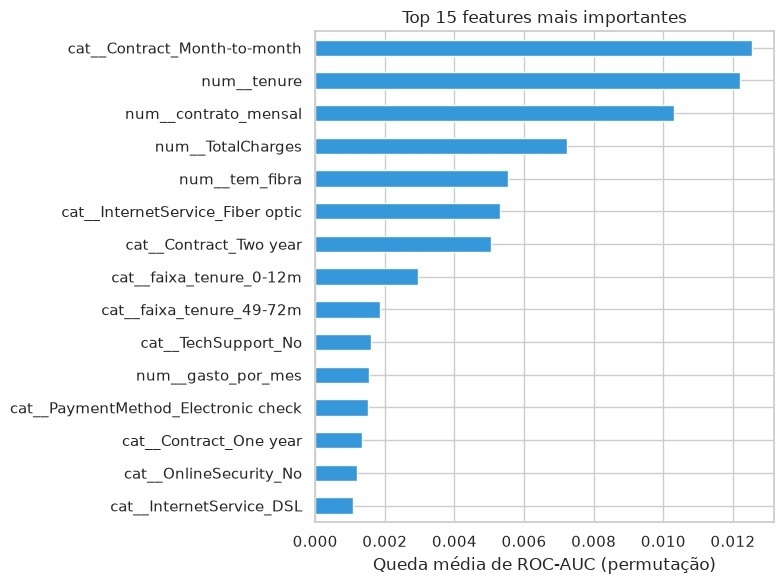

cat__Contract_Month-to-month        0.0126
num__tenure                         0.0122
num__contrato_mensal                0.0103
num__TotalCharges                   0.0072
num__tem_fibra                      0.0055
cat__InternetService_Fiber optic    0.0053
cat__Contract_Two year              0.0051
cat__faixa_tenure_0-12m             0.0030
cat__faixa_tenure_49-72m            0.0019
cat__TechSupport_No                 0.0016
dtype: float64

In [6]:
feats = pre.get_feature_names_out()

imp = permutation_importance(modelo, X_test_t, y_test, n_repeats=10,
                             random_state=42, scoring="roc_auc", n_jobs=-1)

importancias = (pd.Series(imp.importances_mean, index=feats)
                  .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 6))
importancias.head(15).sort_values().plot(kind="barh", ax=ax, color="#3498db")
ax.set_xlabel("Queda média de ROC-AUC (permutação)")
ax.set_title("Top 15 features mais importantes")
plt.tight_layout()
plt.savefig(FIG_DIR / "11_importancia_features.png", dpi=150, bbox_inches="tight")
plt.show()

importancias.head(10).round(4)

In [7]:
if hasattr(modelo, "coef_"):
    odds = pd.Series(np.exp(modelo.coef_[0]), index=feats).sort_values()
    fig, ax = plt.subplots(figsize=(8, 6))
    odds.plot(kind="barh", ax=ax, color=["#e74c3c" if v < 1 else "#2ecc71" for v in odds])
    ax.axvline(1.0, ls="--", c="black", lw=1)
    ax.set_xlabel("Odds ratio (exp(beta))")
    ax.set_title("Regressão Logística: efeito de cada feature no churn")
    ax.set_xticks([0.5, 1, 1.5, 2, 2.5, 3])
    plt.tight_layout()
    plt.savefig(FIG_DIR / "12_odds_ratios.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(odds.round(3).to_frame("odds_ratio").T)
else:
    print(f"{nome_modelo} não expõe coeficientes — use a importância de permutação acima.")

Random Forest não expõe coeficientes — use a importância de permutação acima.


## 4. Conclusões e recomendações de negócio

*(preenchido com base nos resultados obtidos)*

**O modelo**
- Discrimina bem clientes em risco de churn (ROC-AUC ≈ 0,83 no teste) — muito acima do baseline ≈ 0,5.
- O limiar pode ser ajustado para o apetite de negócio: menores limiares ⇒ mais recall
  (mais clientes capturados) em troca de precisão.

**Sinais de risco mais fortes**
1. **Contrato mês a mês** e **poucos meses de casa** (janela crítica dos primeiros 12 meses).
2. **Fibra óptica com gasto mensal alto** sem serviços de valor agregado.
3. **Ausência de TechSupport / OnlineSecurity / Backup**.
4. **Cobrança por boleto eletrônico** em vez de débito automático.

**Ações sugeridas**
- **Onboarding reforçado nos 6 primeiros meses** (quando o churn se concentra).
- **Oferta de migração para contrato anual** com desconto para clientes de risco.
- **Pacote de suporte técnico/segurança** inclusos em teste gratuito por 3 meses.
- **Incentivo ao débito automático** (menor churn associado).
- Rodar o modelo mensalmente e listar o **top-N clientes com maior probabilidade**
  para a equipe de retenção entrar em contato proativamente.

**Como reproduzir**

```bash
cd ~/PROJETOS/churn-prediction
source .venv/bin/activate
jupyter notebook notebooks/
```